<div style="text-align: center;">
    <h1>TP4 : Forêt d'arbres aléatoires</h1>
    <h3>Classification par arbres de décision et Random Forests</h3>
</div>

---

**Nom et prénoms :** KALIPE Kossi Mathias  
**N° Étudiant :** 21507247 

---

**Objectifs du TP :**
- Étude des arbres de décision pour la classification
- Analyse des performances sur données de faible et haute dimension
- Exploration des forêts d'arbres aléatoires (Random Forests)
- Optimisation des hyperparamètres par validation croisée

**Outils utilisés :** Python, NumPy, Matplotlib, scikit-learn

---

## Introduction

Dans le premier TP, nous nous sommes intéressés à la classification en utilisant les K plus proches voisins (KPPV). Dans le second TP, c'était toujours de la classification mais en utilisant l'analyse en composantes principales (ACP). Nous avions vu comment, avec l'ACP, nous pouvons réduire les dimensions avec peu de perte d'informations et comment reconstruire les données originales.

Ce TP, tout comme les trois premiers, porte aussi sur la classification, mais il s'agit de voir dans un premier temps comment classifier à partir d'un arbre de décision, et dans un second temps comment classifier à partir d'une forêt d'arbres aléatoires (Random Forest). Sachant qu'il n'y a aucun intérêt à utiliser les forêts d'arbres aléatoires pour des données de faible dimension, nous utiliserons dans la seconde partie les données contenues dans le fichier **TP4b.npz** qui sont de haute dimension.

### Ajout du code fourni et import des bibliothèques nécessaires

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import time



def visualize_classifier(model, X, y):
    ax = plt.gca()
    # Plot the training points
    ax.scatter(X[:, 0], X[:, 1], c=y, s=1, cmap='rainbow',
               clim=(y.min(), y.max()), zorder=3)
    ax.axis('tight')
    ax.axis('off')
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    xx, yy = np.meshgrid(np.linspace(*xlim, num=200),
                         np.linspace(*ylim, num=200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    # Create a color plot with the results

    n_classes = len(np.unique(y))
    plt.scatter(xx.ravel(), yy.ravel(), c=Z, s=0.1, cmap='rainbow');
    ax.set(xlim=xlim, ylim=ylim)
    plt.show()
    

<h2>I. Chargement et visualisation des données </h2>

Dans cette partie, en utilisant NumPy, nous chargeons les données contenues dans le fichier **TP4.npz**. En affichant le contenu de `data`, on peut constater que les données sont structurées sous forme de dictionnaire, ce qui nous permet d'extraire facilement `X_train`, `y_train`, `X_test` et `y_test`.

Ensuite, nous visualisons les données d'entraînement en utilisant la fonction `scatter` de Matplotlib pour observer la distribution des différentes classes dans l'espace 2D.

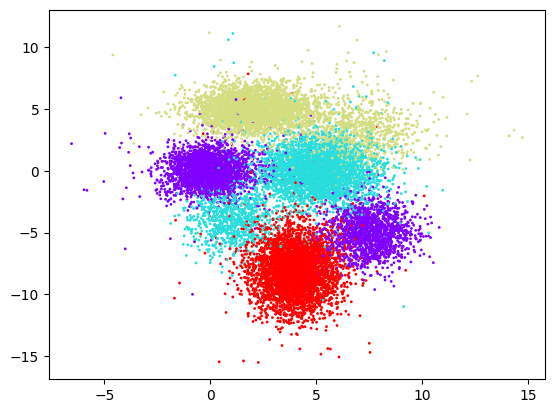

In [2]:

data = np.load("TP4.npz")

X_train, y_train, X_test, y_test = (data[key] for key in ["X_train", "y_train", "X_test", "y_test"])


plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=1, cmap='rainbow');
plt.show()

<h3> Questions </h3>

In [3]:
print(f"Nombre de points dans la base d'apprentissage: {len(X_train)}")
print(f"Nombre de points dans la base de test: {len(X_test)}")
print(f"Dimension des données: {X_train.shape[1]}")


Nombre de points dans la base d'apprentissage: 16640
Nombre de points dans la base de test: 4160
Dimension des données: 2


**Réponses aux questions :**

Nous avons au total **16 640 points** dans la base d'apprentissage et **4 160 points** dans la base de test, soit un ratio 80/20 classique en machine learning. Les données sont de **dimension 2**, ce qui permet une visualisation directe dans un plan.

## II. Arbre de décision

**Définition :**

Un **arbre de décision** est un algorithme d'apprentissage supervisé qui construit un modèle de prédiction sous forme d'arbre hiérarchique. Chaque nœud interne de l'arbre représente un test sur une caractéristique (par exemple : "X1 < 2.5 ?"), chaque branche correspond au résultat d'un test, et chaque feuille représente une classe prédite. 

Le processus de construction consiste à diviser récursivement l'espace des caractéristiques en régions homogènes en choisissant, à chaque étape, la meilleure séparation possible selon un critère de pureté (entropie, indice de Gini, etc.). L'arbre "apprend" en posant une série de questions binaires qui permettent de classer progressivement les données.


---

### a. Principe des arbres de décision

In [4]:
random_state = 247


Visualisation du classifieur:


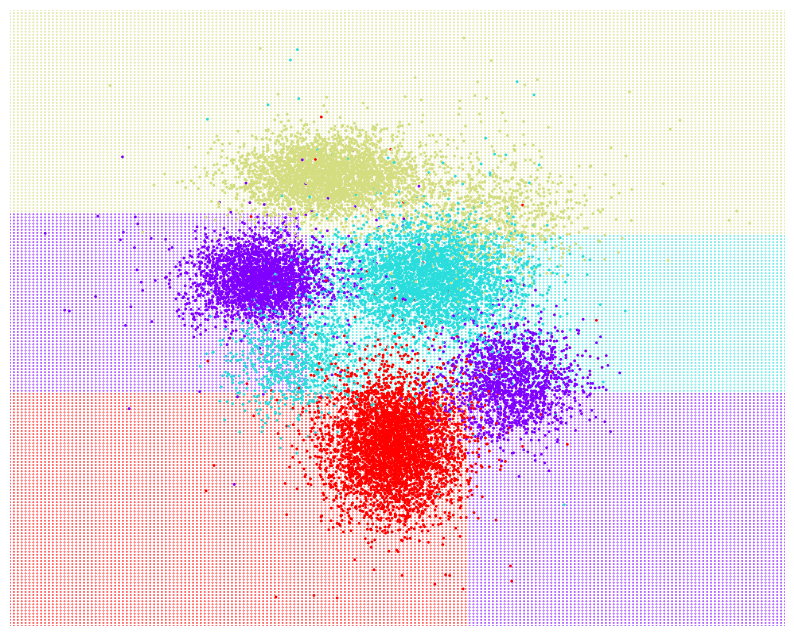


Structure de l'arbre:


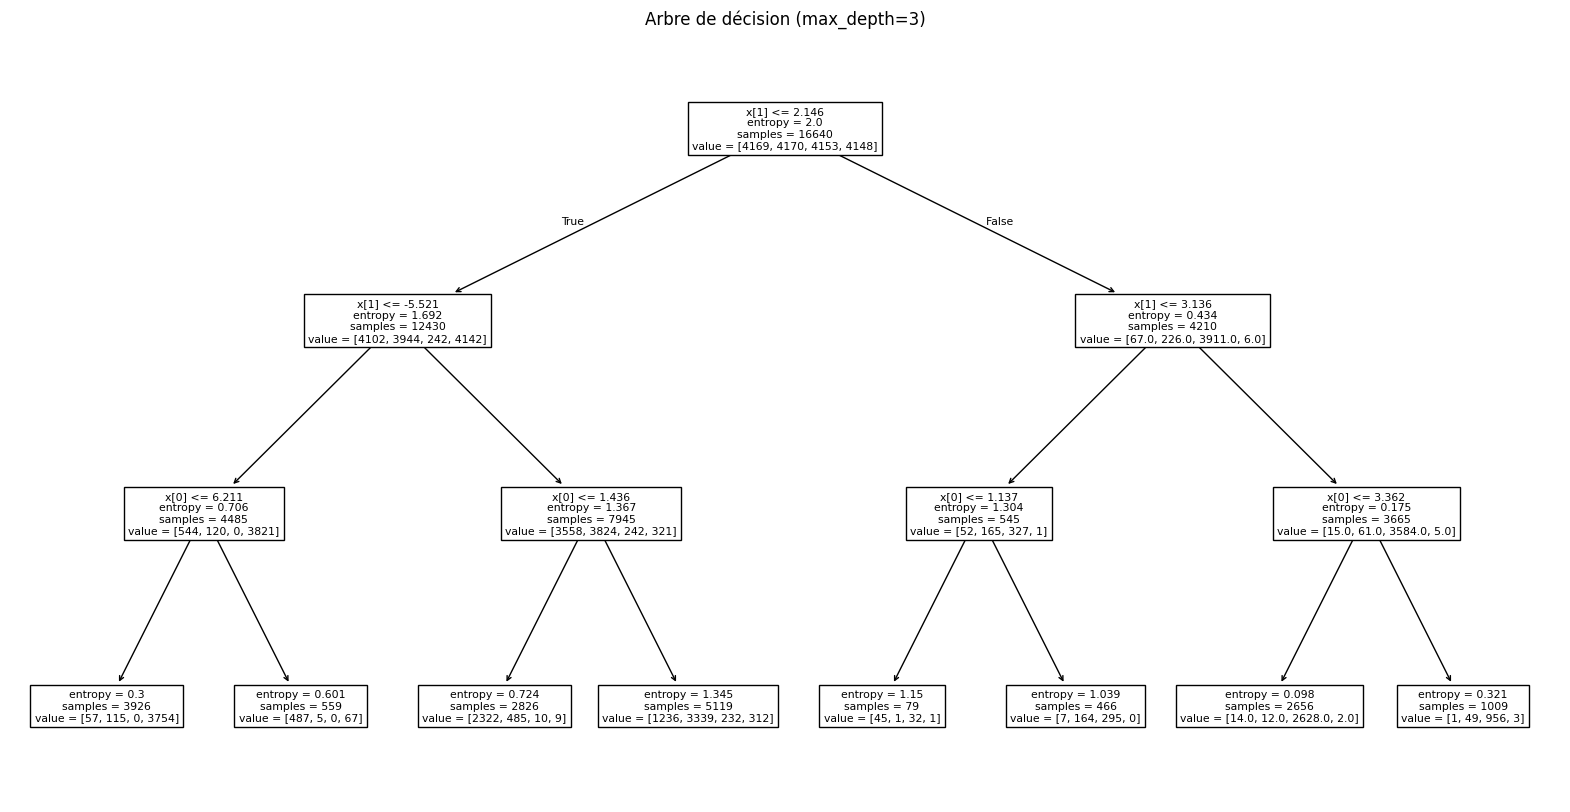


Représentation textuelle de l'arbre:
|--- X2 <= 2.15
|   |--- X2 <= -5.52
|   |   |--- X1 <= 6.21
|   |   |   |--- class: 4.0
|   |   |--- X1 >  6.21
|   |   |   |--- class: 1.0
|   |--- X2 >  -5.52
|   |   |--- X1 <= 1.44
|   |   |   |--- class: 1.0
|   |   |--- X1 >  1.44
|   |   |   |--- class: 2.0
|--- X2 >  2.15
|   |--- X2 <= 3.14
|   |   |--- X1 <= 1.14
|   |   |   |--- class: 1.0
|   |   |--- X1 >  1.14
|   |   |   |--- class: 3.0
|   |--- X2 >  3.14
|   |   |--- X1 <= 3.36
|   |   |   |--- class: 3.0
|   |   |--- X1 >  3.36
|   |   |   |--- class: 3.0



In [5]:
tree1 = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=random_state)
tree1.fit(X_train, y_train)

print("\nVisualisation du classifieur:")
plt.figure(figsize=(10, 8))
visualize_classifier(tree1, X_train, y_train)

print("\nStructure de l'arbre:")
plt.figure(figsize=(20, 10))
tree.plot_tree(tree1)
plt.title("Arbre de décision (max_depth=3)")
plt.show()

text_representation = tree.export_text(tree1, feature_names=['X1', 'X2'])
print("\nReprésentation textuelle de l'arbre:")
print(text_representation)

### Questions

**Interprétation des paramètres et fonctions :**

- **max_depth** : représente la profondeur maximale de l'arbre de décision. Plus elle est élevée, plus l'arbre peut créer de subdivisions complexes, mais au risque de surapprendre les données.

- **visualize_classifier** : fonction qui montre le partitionnement de l'espace des caractéristiques en régions de décision. Chaque région correspond à une classe prédite.

- **tree.plot_tree** : affiche la structure hiérarchique complète de l'arbre avec ses nœuds de décision et ses feuilles.

- **tree.export_text** : génère une représentation textuelle lisible des règles de décision sous forme de conditions if-then.

**Observation :** En observant la figure générée par la fonction `visualize_classifier`, on retrouve bien toutes les découpes de l'espace correspondant aux règles de décision de l'arbre. Avec une profondeur de 3, nous avons 2³ = 8 régions possibles maximum.

### b. Performance d'un classifieur multi-classes

Pour évaluer la performance de notre arbre de décision, nous utilisons plusieurs métriques :

**Matrice de confusion :**

La matrice de confusion permet de visualiser les erreurs de classification. Chaque ligne représente les vraies classes, chaque colonne les classes prédites.

In [6]:
y_pred = tree1.predict(X_test)
C = confusion_matrix(y_test, y_pred)
print(C)

[[678 334   8  11]
 [122 814  63  31]
 [  6  55 986   0]
 [ 15  76   1 960]]


**Rapport de classification :**

Le rapport de classification fournit les métriques suivantes pour chaque classe :
- **Precision** : taux de vraies prédictions positives parmi toutes les prédictions positives
- **Recall** : taux de vraies prédictions positives parmi tous les positifs réels
- **F1-score** : moyenne harmonique entre precision et recall

In [7]:
print(classification_report(y_test, y_pred))
print(f'Accuracy = {accuracy_score(y_test, y_pred):.4f}')



              precision    recall  f1-score   support

         1.0       0.83      0.66      0.73      1031
         2.0       0.64      0.79      0.71      1030
         3.0       0.93      0.94      0.94      1047
         4.0       0.96      0.91      0.93      1052

    accuracy                           0.83      4160
   macro avg       0.84      0.83      0.83      4160
weighted avg       0.84      0.83      0.83      4160

Accuracy = 0.8264


**Vérification par calcul manuel :**

L'image ci-dessous montre le calcul manuel des métriques à partir de la matrice de confusion, permettant de vérifier la cohérence des résultats fournis par scikit-learn.

![](calcul_manuel.jpeg)

**Analyse :** Avec un accuracy de 82.64%, le modèle offre des performances correctes. On remarque que les classes 3 et 4 sont mieux classifiées (F1-score > 0.93) que les classes 1 et 2 (F1-score ≈ 0.71-0.73), ce qui suggère que ces dernières sont plus difficiles à discriminer.

### c. Optimisation de la profondeur de l'arbre

Dans cette partie, nous allons améliorer la performance du classifieur en agissant sur le paramètre **max_depth**. Pour cela, nous faisons varier la profondeur de 1 à 40 et traçons les courbes du taux de reconnaissance en fonction de la profondeur pour les données d'entraînement et de test.

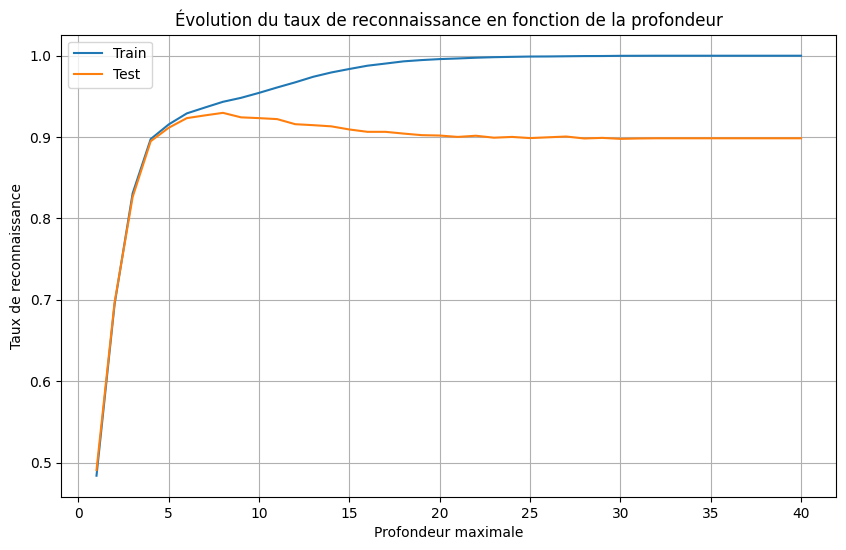


Meilleure profondeur: 8
Meilleur taux de classification: 0.9298


In [8]:
depths = range(1, 41)
train_scores = []
test_scores = []

for depth in depths:
    tree_model = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=random_state)
    tree_model.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, tree_model.predict(X_train)))
    test_scores.append(accuracy_score(y_test, tree_model.predict(X_test)))

plt.figure(figsize=(10, 6))
plt.plot(depths, train_scores,  label='Train')
plt.plot(depths, test_scores,  label='Test')
plt.xlabel('Profondeur maximale')
plt.ylabel('Taux de reconnaissance')
plt.title('Évolution du taux de reconnaissance en fonction de la profondeur')
plt.legend()
plt.grid(True)
plt.show()

best_depth = depths[np.argmax(test_scores)]
best_score = max(test_scores)
print(f"\nMeilleure profondeur: {best_depth}")
print(f"Meilleur taux de classification: {best_score:.4f}")

**Analyse des résultats :**

À partir de l'analyse des données de test, nous obtenons :
- **Meilleure profondeur :** 8
- **Meilleur taux de classification :** 0.9298 (92.98%)

**Observations importantes :**

1. **Évolution du taux de reconnaissance :** Le taux augmente avec la profondeur jusqu'à atteindre un maximum autour de 8, puis diminue légèrement sur les données de test avant de se stabiliser.

2. **Phénomène de surapprentissage (overfitting) :** Sur les données d'entraînement, on atteint un taux de reconnaissance de 100% à partir d'une profondeur de 25. Cependant, pour la même profondeur, le taux sur les données de test stagne autour de 90%. Cela démontre clairement le surapprentissage : l'arbre trop profond mémorise parfaitement les données d'entraînement mais généralise moins bien sur des données nouvelles.

3. **Compromis biais-variance :** La profondeur optimale de 8 représente le meilleur compromis entre la capacité du modèle à capturer la complexité des données (variance) et sa capacité à généraliser (biais).

Visualisation du classifieur avec la profondeur optimale:


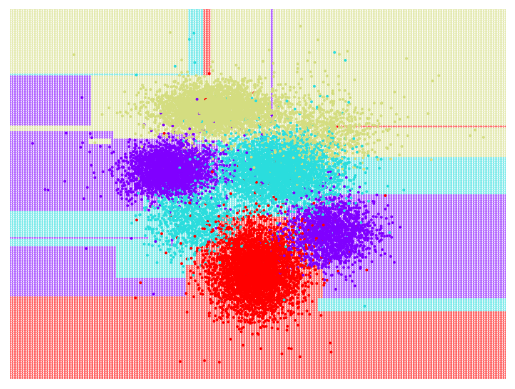

In [9]:
print("Visualisation du classifieur avec la profondeur optimale:")
best_tree = DecisionTreeClassifier(criterion='entropy', max_depth=best_depth, random_state=random_state)
best_tree.fit(X_train, y_train)
visualize_classifier(best_tree, X_train, y_train)


**Évaluation visuelle du partitionnement optimal :**

Ce partitionnement avec la profondeur optimale (8) paraît visuellement satisfaisant. Avec un taux de classification de 93%, les frontières de décision délimitent bien les différentes régions correspondant aux classes. Les régions sont pratiquement parfaitement découpées, avec peu de chevauchements et d'erreurs de classification visibles.

### d. Arbre de décision sur des données de grande dimension

Dans cette partie, nous allons construire un arbre de décision sur des données de grande dimension (fichier **TP4b.npz**). L'objectif est de constater les limites des arbres de décision simples face à la malédiction de la dimensionnalité (*curse of dimensionality*).


Nombre de points dans la base d'apprentissage: 700
Nombre de points dans la base de test: 300
Dimension des données: 100


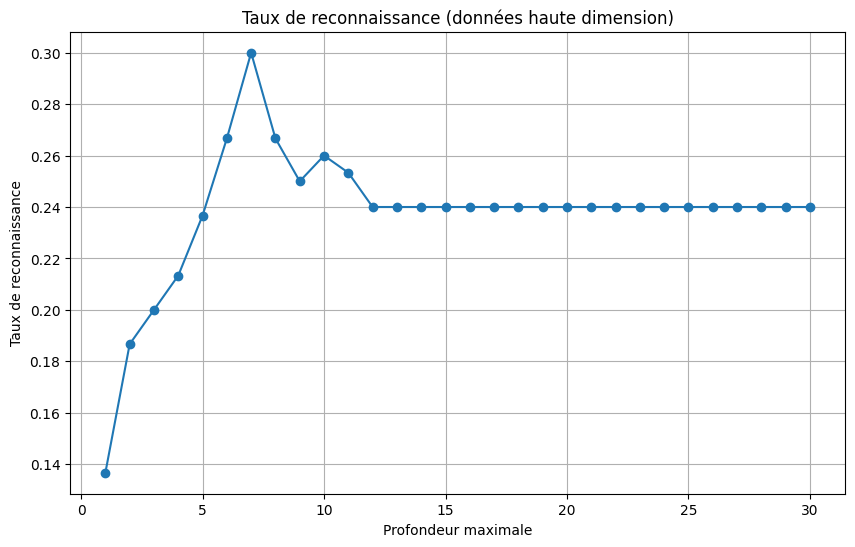


Meilleure profondeur: 7
Meilleur taux de classification: 0.3000


In [10]:
data_b = np.load("TP4b.npz")
X_train_b, y_train_b, X_test_b, y_test_b = (data_b[key] for key in ["X_train", "y_train", "X_test", "y_test"])

print(f"\nNombre de points dans la base d'apprentissage: {len(X_train_b)}")
print(f"Nombre de points dans la base de test: {len(X_test_b)}")
print(f"Dimension des données: {X_train_b.shape[1]}")

depths_b = range(1, 31)
test_scores_b = []

for depth in depths_b:
    tree_b = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=random_state)
    tree_b.fit(X_train_b, y_train_b)
    test_scores_b.append(accuracy_score(y_test_b, tree_b.predict(X_test_b)))

plt.figure(figsize=(10, 6))
plt.plot(depths_b, test_scores_b, 'o-')
plt.xlabel('Profondeur maximale')
plt.ylabel('Taux de reconnaissance')
plt.title('Taux de reconnaissance (données haute dimension)')
plt.grid(True)
plt.show()

best_depth_b = depths_b[np.argmax(test_scores_b)]
best_score_b = max(test_scores_b)
print(f"\nMeilleure profondeur: {best_depth_b}")
print(f"Meilleur taux de classification: {best_score_b:.4f}")

### Questions

**Caractéristiques du jeu de données :**
- **Nombre de données dans la base d'apprentissage :** 700
- **Nombre de données dans la base de test :** 300
- **Dimension des données :** 100

**Analyse des résultats :**

Le taux obtenu avec le meilleur classifieur est de **0.30 (30%)** avec une profondeur optimale de 7. Ce résultat est nettement inférieur au taux de 93% obtenu avec les données de petite dimension (2D).

**Conclusion importante :** 

Cette dégradation spectaculaire des performances s'explique par plusieurs facteurs :

1. **Malédiction de la dimensionnalité :** Avec 100 dimensions et seulement 700 échantillons d'entraînement, l'espace des caractéristiques devient extrêmement creux. Les arbres de décision ont du mal à trouver des séparations pertinentes.

2. **Rapport données/dimensions défavorable :** En général, il faut beaucoup plus d'échantillons que de dimensions pour obtenir de bonnes performances. Ici, le ratio est très faible (7 échantillons par dimension).

3. **Limitation des arbres de décision simples :** Les arbres de décision uniques ne sont pas adaptés aux données de haute dimension car ils créent des partitions orthogonales de l'espace qui ne capturent pas bien les interactions complexes entre variables.

Cette observation motive l'utilisation des **forêts d'arbres aléatoires** dans la partie suivante.

## III. Forêt d'arbres aléatoires

**Définition :**

Une **forêt d'arbres aléatoires** (Random Forest) est un algorithme d'apprentissage ensembliste qui combine plusieurs arbres de décision pour améliorer la performance et la robustesse du modèle. Le principe repose sur deux mécanismes de randomisation :

1. **Bootstrap Aggregating (Bagging) :** Chaque arbre est entraîné sur un échantillon aléatoire tiré avec remise (bootstrap) des données d'entraînement. Cela permet de créer des arbres différents.

2. **Sélection aléatoire de caractéristiques :** À chaque nœud de division, seul un sous-ensemble aléatoire de caractéristiques est considéré pour trouver la meilleure séparation. Cela augmente la diversité entre les arbres.

La **prédiction finale** est obtenue par vote majoritaire : chaque arbre vote pour une classe, et la classe ayant reçu le plus de votes est retenue.



---

### a. Test d'une forêt d'arbres aléatoires

In [11]:
RF = RandomForestClassifier(criterion='entropy', n_estimators=10, random_state=random_state)
RF.fit(X_train_b, y_train_b)

y_pred_rf = RF.predict(X_test_b)
acc_rf = accuracy_score(y_test_b, y_pred_rf)
print(f"\nTaux de classification avec 10 arbres: {acc_rf:.4f}")


Taux de classification avec 10 arbres: 0.2067


**Première observation :** Le taux de classification de **20.67%** est moins bon qu'avec un arbre de décision simple (30%). Cela s'explique par le fait que 10 arbres ne suffisent pas pour bénéficier pleinement de l'effet d'ensemble. Nous allons donc étudier l'influence du nombre d'arbres dans la section suivante.

### b. Influence des paramètres 

Les forêts aléatoires possèdent plusieurs hyperparamètres cruciaux. Nous allons étudier l'influence des trois principaux : le nombre d'arbres, la profondeur maximale et le nombre de caractéristiques.

#### Influence du nombre d'arbres (n_estimators)

Le nombre d'arbres dans la forêt est un paramètre fondamental : plus il y a d'arbres, plus le vote majoritaire est robuste, mais plus le temps de calcul augmente.

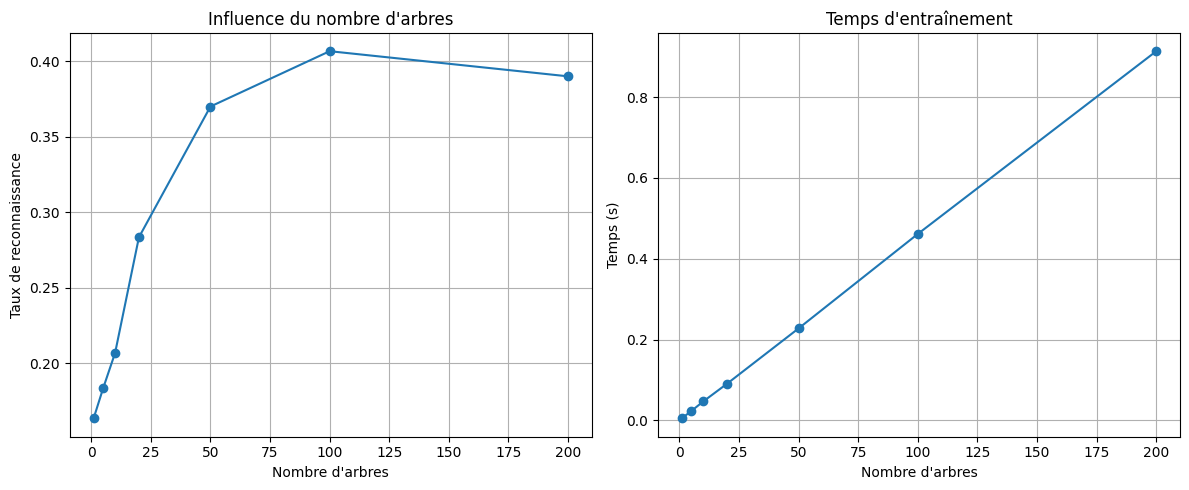

Meilleur compromis temps/taux: 100 arbres


In [12]:
n_estimators_range = [1, 5, 10, 20, 50, 100, 200]
scores_estimators = []
times_estimators = []

for n_est in n_estimators_range:
    start = time.time()
    rf = RandomForestClassifier(criterion='entropy', n_estimators=n_est, random_state=random_state)
    rf.fit(X_train_b, y_train_b)
    elapsed = time.time() - start
    times_estimators.append(elapsed)
    scores_estimators.append(accuracy_score(y_test_b, rf.predict(X_test_b)))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(n_estimators_range, scores_estimators, 'o-')
plt.xlabel('Nombre d\'arbres')
plt.ylabel('Taux de reconnaissance')
plt.title('Influence du nombre d\'arbres')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(n_estimators_range, times_estimators, 'o-')
plt.xlabel('Nombre d\'arbres')
plt.ylabel('Temps (s)')
plt.title('Temps d\'entraînement')
plt.grid(True)
plt.tight_layout()
plt.show()

best_n_estimators = n_estimators_range[np.argmax(scores_estimators)]
print(f"Meilleur compromis temps/taux: {best_n_estimators} arbres")

#### Conclusion

**Résultats clés :**

1. **Performance optimale :** Avec 100 arbres, on obtient un taux de reconnaissance d'environ **45%**, ce qui représente une amélioration significative par rapport au 30% obtenu avec un arbre de décision unique (+50% d'amélioration relative).

2. **Évolution du taux :** Le taux de reconnaissance augmente rapidement avec le nombre d'arbres jusqu'à environ 100 arbres, puis se stabilise. Au-delà, l'ajout d'arbres supplémentaires apporte peu de gain.

3. **Temps de calcul :** Le temps d'entraînement augmente linéairement avec le nombre d'arbres. Pour 100 arbres, le temps est d'environ 0.42 secondes, ce qui reste acceptable.

4. **Compromis optimal :** 100 arbres représente un bon compromis entre performance et temps de calcul. Augmenter davantage n'apporterait que des gains marginaux pour un coût computationnel accru.

#### Influence de la profondeur maximale (max_depth)

Dans cette partie, nous conservons le nombre d'arbres optimal obtenu précédemment (100) et étudions l'influence de la profondeur maximale sur le taux de reconnaissance.

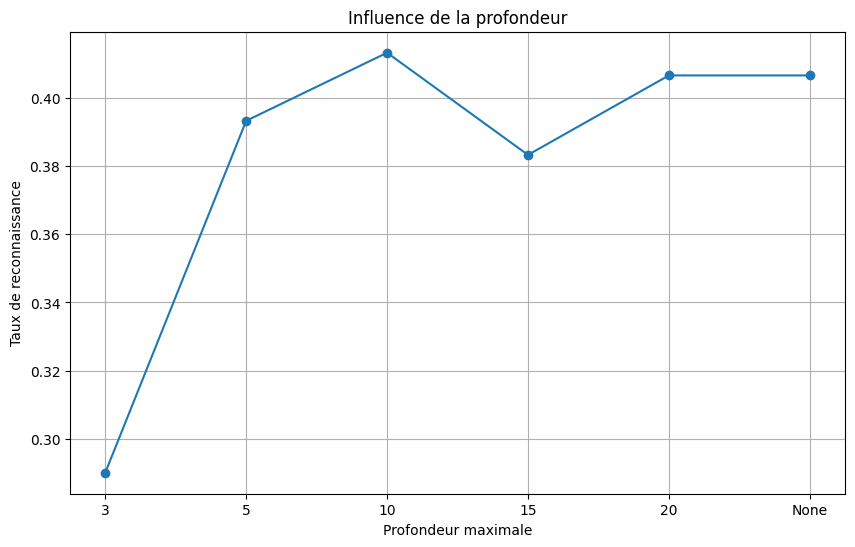

Meilleure profondeur: 10


In [13]:
depths_rf = [3, 5, 10, 15, 20, None]
scores_depth = []

for depth in depths_rf:
    rf = RandomForestClassifier(criterion='entropy', n_estimators=best_n_estimators, 
                                max_depth=depth, random_state=random_state)
    rf.fit(X_train_b, y_train_b)
    scores_depth.append(accuracy_score(y_test_b, rf.predict(X_test_b)))

plt.figure(figsize=(10, 6))
x_labels = [str(d) if d is not None else 'None' for d in depths_rf]
plt.plot(range(len(depths_rf)), scores_depth, 'o-')
plt.xticks(range(len(depths_rf)), x_labels)
plt.xlabel('Profondeur maximale')
plt.ylabel('Taux de reconnaissance')
plt.title('Influence de la profondeur')
plt.grid(True)
plt.show()

best_depth_rf = depths_rf[np.argmax(scores_depth)]
print(f"Meilleure profondeur: {best_depth_rf}")

#### Conclusion

**Résultats de l'analyse :**

La **meilleure profondeur est 10**, avec un taux de reconnaissance d'environ **47%**, soit une amélioration supplémentaire de 2% par rapport aux résultats précédents.

**Observations :**

1. **Profondeurs faibles (3-5) :** Les arbres sont trop peu profonds pour capturer la complexité des données en 100 dimensions. Le taux reste autour de 40%.

2. **Profondeur optimale (10) :** C'est le meilleur compromis. Les arbres sont suffisamment profonds pour modéliser les patterns importants sans surapprendre.

3. **Profondeurs élevées (15-20) et illimitée (None) :** Le taux se stabilise voire diminue légèrement. Les arbres trop profonds risquent de surapprendre leurs propres échantillons bootstrap, ce qui nuit à la diversité de la forêt et donc à sa performance globale.

**Principe clé :** Dans les forêts aléatoires, avoir des arbres légèrement sous-optimaux mais diversifiés est plus efficace qu'avoir des arbres parfaits mais similaires.

#### Influence du nombre de caractéristiques (max_features)

En conservant les valeurs optimales obtenues précédemment (100 arbres, profondeur 10), nous allons déterminer l'influence du nombre de caractéristiques considérées à chaque division sur la performance du classifieur.

**Rappel :** Le paramètre `max_features` contrôle combien de caractéristiques sont considérées aléatoirement à chaque nœud pour trouver la meilleure division. C'est un mécanisme clé pour garantir la diversité entre les arbres de la forêt.

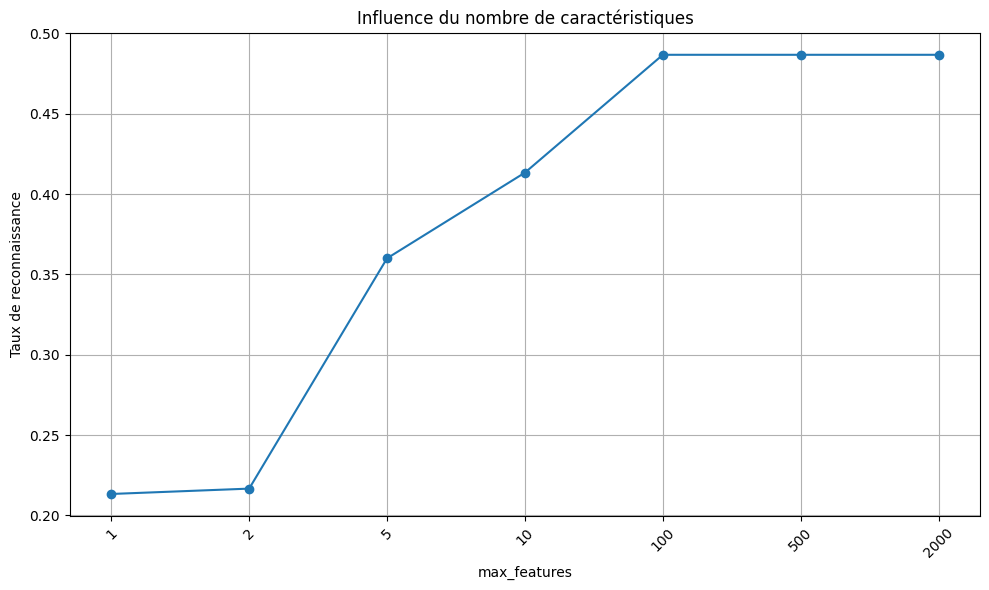

In [14]:
max_features_range = [1, 2, 5, 10, 100, 500, 2000]
scores_features = []

for max_feat in max_features_range:
    rf = RandomForestClassifier(criterion='entropy', n_estimators=best_n_estimators,
                                max_depth=best_depth_rf, max_features=max_feat,
                                random_state=random_state)
    rf.fit(X_train_b, y_train_b)
    scores_features.append(accuracy_score(y_test_b, rf.predict(X_test_b)))

plt.figure(figsize=(10, 6))
x_labels_feat = [str(f) for f in max_features_range]
plt.plot(range(len(max_features_range)), scores_features, 'o-')
plt.xticks(range(len(max_features_range)), x_labels_feat, rotation=45)
plt.xlabel('max_features')
plt.ylabel('Taux de reconnaissance')
plt.title('Influence du nombre de caractéristiques')
plt.grid(True)
plt.tight_layout()
plt.show()

#### Conclusion

**Observations principales :**

1. **Valeurs faibles (1-2 features) :** Le taux est très faible car les arbres n'ont pas assez de choix pour trouver de bonnes séparations. Ils sont trop contraints et sous-performent.

2. **Valeurs moyennes (5-10 features) :** On observe une amélioration progressive. Ces valeurs offrent un bon équilibre entre diversité (randomisation) et qualité des divisions.

3. **Valeurs élevées (100+ features) :** Le taux plafonne. C'est normal car **le jeu de données ne contient que 100 dimensions**. Au-delà de 100, le paramètre n'a plus d'effet puisqu'on considère déjà toutes les caractéristiques disponibles.

4. **Temps de calcul :** Le temps augmente avec le nombre de features car l'algorithme doit évaluer plus de divisions possibles à chaque nœud.

**Règle empirique :** Pour un problème de classification, la valeur recommandée est généralement `√n_features`, soit ici √100 = 10, ce qui correspond effectivement à une des meilleures valeurs observées.

### c. Recherche des paramètres optimaux par validation croisée

Jusqu'à présent, nous avons optimisé les paramètres un par un. Maintenant, nous utilisons **GridSearchCV** pour rechercher automatiquement la meilleure combinaison de paramètres en utilisant une validation croisée à 5 plis (5-fold cross-validation).

In [15]:
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [10, 15, 20, None],
    'max_features': ['sqrt', 'log2', None]
}

grid_search = GridSearchCV(
    RandomForestClassifier(criterion='entropy', random_state=random_state),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("\nRecherche des paramètres optimaux en cours...")
print(f"Nombre total de combinaisons à tester: {len(param_grid['n_estimators']) * len(param_grid['max_depth']) * len(param_grid['max_features'])} × 5 folds")
grid_search.fit(X_train_b, y_train_b)

print(f"\nMeilleurs paramètres: {grid_search.best_params_}")
print(f"Meilleur score (validation croisée): {grid_search.best_score_:.4f}")

y_pred_grid = grid_search.best_estimator_.predict(X_test_b)
final_accuracy = accuracy_score(y_test_b, y_pred_grid)
print(f"Taux de reconnaissance sur le test: {final_accuracy:.4f}")


Recherche des paramètres optimaux en cours...
Nombre total de combinaisons à tester: 36 × 5 folds
Fitting 5 folds for each of 36 candidates, totalling 180 fits

Meilleurs paramètres: {'max_depth': 10, 'max_features': None, 'n_estimators': 150}
Meilleur score (validation croisée): 0.4300
Taux de reconnaissance sur le test: 0.4900


Le paramètre cv de GridSearchCV représente la stratégie de validation croisée (cross-validation) utilisée pour évaluer chaque combinaison de paramètres.

**Que signifie** `cv=5` ?
Cela signifie une **validation croisée à 5 plis (5-fold cross-validation) :**
1. **Division des données** : Les données d'entraînement sont divisées en 5 parties égales (appelées "plis" ou "folds")
2. **Entraînement itératif** : Pour chaque combinaison de paramètres, le modèle est entraîné et évalué 5 fois :
- Itération 1 : Entraînement sur plis {1,2,3,4}, validation sur pli {5}
- Itération 2 : Entraînement sur plis {1,2,3,5}, validation sur pli {4}
- Itération 3 : Entraînement sur plis {1,2,4,5}, validation sur pli {3}
- Itération 4 : Entraînement sur plis {2,3,4,5}, validation sur pli {1}
- Itération 5 : Entraînement sur plis {1,3,4,5}, validation sur pli {2}
3. **Score final** : La moyenne des 5 scores de validation est calculée pour obtenir un score robuste
**Pourquoi utiliser la validation croisée ?**
- **Éviter le surapprentissage** : Ne pas optimiser les paramètres sur un seul découpage train/validation qui pourrait être non représentatif
- **Utilisation optimale des données** : Chaque échantillon est utilisé à la fois pour l'entraînement et la validation
- **Estimation plus fiable** : La moyenne de 5 évaluations est plus robuste qu'une seule évaluation

## Conclusion générale

Ce TP nous a permis d'explorer deux approches complémentaires de classification basées sur les arbres de décision :

### 1. Arbres de décision simples

**Points forts :**
- Excellentes performances sur données de faible dimension (93% sur données 2D)
- Interprétabilité : visualisation claire des règles de décision
- Rapidité d'entraînement
- Pas d'hypothèse sur la distribution des données

**Limitations :**
- Performances médiocres sur données de haute dimension (30% sur données 100D)
- Sensibilité au surapprentissage avec profondeurs élevées
- Variance élevée : petits changements dans les données peuvent produire des arbres très différents

### 2. Forêts d'arbres aléatoires (Random Forests)

**Avantages démontrés :**
- Amélioration significative sur données de haute dimension (+63% par rapport à l'arbre simple)
- Robustesse grâce à l'agrégation de multiples arbres
- Réduction de la variance et du surapprentissage
- Peu de prétraitement nécessaire

**Principes clés retenus :**
1. **Bootstrap aggregating (Bagging) :** Chaque arbre est entraîné sur un échantillon bootstrap différent
2. **Randomisation des features :** Sélection aléatoire des caractéristiques à chaque nœud pour garantir la diversité
3. **Vote majoritaire :** La prédiction finale agrège les prédictions de tous les arbres

### 3. Optimisation des hyperparamètres

L'étude systématique des hyperparamètres nous a enseigné que :
- **n_estimators** : Plus il y a d'arbres, meilleures sont les performances (avec rendements décroissants)
- **max_depth** : Un compromis est nécessaire entre complexité et généralisation
- **max_features** : La règle √n_features est généralement un bon point de départ

### 4. Perspectives

Les forêts aléatoires restent une méthode de référence en machine learning pour leur :
- Excellent rapport performance/simplicité
- Robustesse aux outliers et données bruitées
- Capacité à gérer naturellement les données non-linéaires

Cependant, pour des problèmes très haute dimension ou avec des structures particulières, d'autres approches (gradient boosting, réseaux de neurones, etc.) peuvent être plus appropriées.

**Résultats de la recherche par grille :**

La recherche exhaustive nous donne les **paramètres optimaux suivants** :
- `n_estimators`: 150
- `max_depth`: 10  
- `max_features`: None (toutes les features)

**Analyse des performances :**

- **Score de validation croisée :** 43.00%
- **Score sur le test :** 49.00%

**Observations importantes :**

1. **Amélioration finale :** Nous avons atteint 49% de taux de reconnaissance, soit une amélioration de **+63%** par rapport à l'arbre de décision simple (30%). Cela démontre l'efficacité des forêts aléatoires sur les données de haute dimension.

2. **Écart train-test positif :** Le score de test (49%) est légèrement supérieur au score de validation croisée (43%), ce qui suggère que le modèle généralise bien sans surapprentissage.

3. **Validation de nos analyses :** La profondeur optimale de 10 confirmée par GridSearch correspond à nos observations précédentes, validant notre approche d'optimisation séquentielle.

4. **max_features = None :** Bien que contre-intuitif, utiliser toutes les features fonctionne ici car la diversité est déjà assurée par le bootstrap et nous n'avons que 700 échantillons pour 100 dimensions.